In [73]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.lda import LDA
from src.knn import KNN
from src.gmm import GMMClassifier

DATA_FOLDER = Path(
    r"C:\Users\hp\OneDrive\Desktop\ml lab8\team8\data\Dataset2"
)

In [74]:
def load_split(split_name):
    feature_path = DATA_FOLDER / f"{split_name}_data.csv"
    label_path = DATA_FOLDER / f"{split_name}_label.csv"

    # Read features and labels.
    features = pd.read_csv(
        feature_path,
        header=None
    ).to_numpy(dtype=float)

    label_table = pd.read_csv(
        label_path,
        header=None
    )

    if label_table.shape[1] != 1:
        raise ValueError(
            f"{split_name}: expected one label column."
        )

    raw_labels = label_table.to_numpy(dtype=float).ravel()

    # Check sample counts.
    if len(features) == 0:
        raise ValueError(f"{split_name}: dataset is empty.")

    if len(features) != len(raw_labels):
        raise ValueError(
            f"{split_name}: feature and label counts differ."
        )

    # Check numerical values.
    if not np.isfinite(features).all():
        raise ValueError(
            f"{split_name}: features contain missing "
            "or infinite values."
        )

    if not np.isfinite(raw_labels).all():
        raise ValueError(
            f"{split_name}: labels contain missing "
            "or infinite values."
        )

    # Check labels before converting them to integers.
    if not np.equal(raw_labels, np.floor(raw_labels)).all():
        raise ValueError(
            f"{split_name}: labels must be integer-valued."
        )

    labels = raw_labels.astype(int)

    return features, labels


# Load the supplied splits directly.
X_train, y_train = load_split("train")
X_val, y_val = load_split("val")
X_test, y_test = load_split("test")

n_features = X_train.shape[1]
class_labels = np.unique(y_train)
n_classes = len(class_labels)

# Validate the expected dataset structure.
if n_features != 36:
    raise ValueError(
        f"Expected 36 features; found {n_features}."
    )

if not np.array_equal(class_labels, np.arange(5)):
    raise ValueError(
        f"Expected training classes 0–4; found {class_labels}."
    )

for name, features, labels in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Testing", X_test, y_test)
]:
    if features.shape[1] != n_features:
        raise ValueError(
            f"{name}: inconsistent number of features."
        )

    if not np.isin(labels, class_labels).all():
        raise ValueError(
            f"{name}: found a class absent from training data."
        )

    print(
        f"{name}: features {features.shape}, "
        f"labels {labels.shape}"
    )

print(f"\nNumber of features: {n_features}")
print(f"Number of classes: {n_classes}")
print("Class labels:", class_labels)

# Preview training data only.
feature_names = [
    f"x{i + 1}" for i in range(n_features)
]

preview = pd.DataFrame(
    X_train[:5],
    columns=feature_names
)

preview["label"] = y_train[:5]

print("\nFirst five training samples:")
print(preview.to_string(index=False))

Training: features (2000, 36), labels (2000,)
Validation: features (500, 36), labels (500,)
Testing: features (500, 36), labels (500,)

Number of features: 36
Number of classes: 5
Class labels: [0 1 2 3 4]

First five training samples:
      x1       x2       x3       x4       x5       x6       x7       x8       x9      x10      x11      x12      x13      x14      x15      x16      x17      x18      x19      x20      x21      x22      x23      x24      x25      x26      x27      x28      x29      x30      x31      x32      x33      x34      x35      x36  label
0.045563 0.007412 0.126662 0.091336 0.255243 0.197489 0.255243 0.135334 0.041368 0.056467 0.139864 0.129689 0.197060 0.072421 0.255243 0.255243 0.249862 0.039226 0.255243 0.255243 0.091476 0.113129 0.127547 0.015978 0.091827 0.032247 0.115103 0.255243 0.255243 0.200831 0.154036 0.050882 0.113297 0.059047 0.255243 0.192657      0
0.171717 0.299581 0.299581 0.086474 0.038040 0.000030 0.002403 0.000120 0.005000 0.011820 0.048636 0.0

In [75]:
split_rows = []

for name, X_split, y_split in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Testing", X_test, y_test)
]:
    row = {
        "Split": name,
        "Samples": len(y_split),
        "Features": X_split.shape[1]
    }

    for label in class_labels:
        row[f"Class {label}"] = np.sum(y_split == label)

    split_rows.append(row)

split_summary = pd.DataFrame(split_rows)
print(split_summary.to_string(index=False))

     Split  Samples  Features  Class 0  Class 1  Class 2  Class 3  Class 4
  Training     2000        36      400      400      400      400      400
Validation      500        36      100      100      100      100      100
   Testing      500        36      100      100      100      100      100


In [76]:
train_mean = X_train.mean(axis=0)
train_std = X_train.std(axis=0)

constant_features = train_std == 0
train_std_safe = np.where(constant_features, 1.0, train_std)

X_train_scaled = (X_train - train_mean) / train_std_safe
X_val_scaled = (X_val - train_mean) / train_std_safe
X_test_scaled = (X_test - train_mean) / train_std_safe

In [77]:
def accuracy_score_manual(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if y_true.shape != y_pred.shape:
        raise ValueError(
            "Actual and predicted labels must have the same shape."
        )

    return np.mean(y_true == y_pred)


def confusion_matrix_manual(y_true, y_pred):
    label_to_index = {
        label: index
        for index, label in enumerate(class_labels)
    }

    matrix = np.zeros(
        (len(class_labels), len(class_labels)),
        dtype=int
    )

    for actual, predicted in zip(y_true, y_pred):
        matrix[
            label_to_index[actual],
            label_to_index[predicted]
        ] += 1

    return matrix


def show_evaluation(name, y_true, y_pred):
    accuracy = accuracy_score_manual(y_true, y_pred)
    matrix = confusion_matrix_manual(y_true, y_pred)

    correct = int(np.sum(y_true == y_pred))
    errors = len(y_true) - correct

    print(f"{name} validation accuracy: {100 * accuracy:.3f}%")
    print(f"Correct predictions: {correct}")
    print(f"Incorrect predictions: {errors}")

    print("\nConfusion matrix:")

    print(pd.DataFrame(
        matrix,
        index=[
            f"Actual {label}"
            for label in class_labels
        ],
        columns=[
            f"Predicted {label}"
            for label in class_labels
        ]
    ))

    return accuracy

In [78]:
#LDA
# Learn using training data only.
lda_model = LDA(regularization=1e-6)

lda_model.fit(
    X_train_scaled,
    y_train
)

# Predict validation labels.
lda_val_predictions = lda_model.predict(
    X_val_scaled
)

# Evaluate validation predictions.
lda_val_accuracy = show_evaluation(
    "LDA",
    y_val,
    lda_val_predictions
)

# Start the classifier comparison table.
validation_results = [{
    "Classifier": "LDA",
    "Setting": "Shared covariance",
    "Validation accuracy (%)": 100 * lda_val_accuracy
}]

LDA validation accuracy: 52.800%
Correct predictions: 264
Incorrect predictions: 236

Confusion matrix:
          Predicted 0  Predicted 1  Predicted 2  Predicted 3  Predicted 4
Actual 0           36           11           14           18           21
Actual 1            8           55           16            6           15
Actual 2            5            8           59           11           17
Actual 3           15            5           10           60           10
Actual 4           13            8           19            6           54


In [79]:
#KNN
# Train KNN by storing the training samples.
knn_model = KNN(batch_size=128)
knn_model.fit(X_train_scaled, y_train)

neighbor_values = [3, 5, 7, 11]

# Calculate predictions for all candidate neighbour counts.
knn_val_predictions = knn_model.predict_for_k_values(
    X_val_scaled,
    neighbor_values
)

knn_rows = []

for k in neighbor_values:
    predictions = knn_val_predictions[k]

    correct = int(np.sum(predictions == y_val))
    errors = len(y_val) - correct

    accuracy = accuracy_score_manual(
        y_val,
        predictions
    )

    knn_rows.append({
        "Neighbours": k,
        "Correct": correct,
        "Errors": errors,
        "Validation accuracy (%)": 100 * accuracy
    })

knn_validation_table = pd.DataFrame(knn_rows)

print("KNN validation comparison:")
print(knn_validation_table.to_string(index=False))

# Highest accuracy first; smaller k wins an accuracy tie.
ranked_knn_candidates = knn_validation_table.sort_values(
    by=["Validation accuracy (%)", "Neighbours"],
    ascending=[False, True]
)

best_k = int(
    ranked_knn_candidates.iloc[0]["Neighbours"]
)

print(f"\nSelected number of neighbours: {best_k}\n")

best_knn_val_accuracy = show_evaluation(
    f"KNN (k={best_k})",
    y_val,
    knn_val_predictions[best_k]
)



KNN validation comparison:
 Neighbours  Correct  Errors  Validation accuracy (%)
          3      246     254                     49.2
          5      251     249                     50.2
          7      268     232                     53.6
         11      270     230                     54.0

Selected number of neighbours: 11

KNN (k=11) validation accuracy: 54.000%
Correct predictions: 270
Incorrect predictions: 230

Confusion matrix:
          Predicted 0  Predicted 1  Predicted 2  Predicted 3  Predicted 4
Actual 0           50            4           13            7           26
Actual 1            7           57           16            4           16
Actual 2           11            8           45            9           27
Actual 3           13            4           12           58           13
Actual 4           17            9            9            5           60


In [80]:
#GMM
component_values = [1, 2, 3, 4]

gmm_models = {}
gmm_val_predictions = {}
gmm_rows = []

for components in component_values:
    print(
        f"Training GMM with {components} component(s) per class...",
        flush=True
    )

    model = GMMClassifier(
        n_components=components,
        max_iter=300,
        tol=1e-5,
        regularization=1e-4
    )

    try:
        model.fit(X_train_scaled, y_train)

        predictions = model.predict(X_val_scaled)

        accuracy = accuracy_score_manual(
            y_val,
            predictions
        )

        all_converged = all(
            class_model.converged_
            for class_model in model.models_
        )

        gmm_models[components] = model
        gmm_val_predictions[components] = predictions

        row = {
            "Components per class": components,
            "Validation accuracy (%)": 100 * accuracy,
            "All classes converged": all_converged,
            "Status": (
                "OK" if all_converged else "Iteration limit"
            )
        }

        for class_label, class_model in zip(
            model.classes_,
            model.models_
        ):
            row[f"Class {class_label} EM updates"] = (
                class_model.n_iter_
            )

    except (ValueError, np.linalg.LinAlgError) as error:
        print(
            f"  Candidate failed: {error}",
            flush=True
        )

        row = {
            "Components per class": components,
            "Validation accuracy (%)": np.nan,
            "All classes converged": False,
            "Status": str(error)
        }

    gmm_rows.append(row)

gmm_validation_table = pd.DataFrame(gmm_rows)

print("\nGMM validation comparison:")
print(
    gmm_validation_table.round(3).to_string(index=False)
)

Training GMM with 1 component(s) per class...
Training GMM with 2 component(s) per class...
Training GMM with 3 component(s) per class...
Training GMM with 4 component(s) per class...

GMM validation comparison:
 Components per class  Validation accuracy (%)  All classes converged Status  Class 0 EM updates  Class 1 EM updates  Class 2 EM updates  Class 3 EM updates  Class 4 EM updates
                    1                     54.6                   True     OK                   1                   1                   1                   1                   1
                    2                     51.8                   True     OK                   5                   3                   4                   5                   4
                    3                     51.4                   True     OK                  39                   4                  15                  38                  12
                    4                     50.6                   True     OK    

In [81]:
# Consider candidates where all five class models converged.
eligible_candidates = gmm_validation_table[
    gmm_validation_table["All classes converged"]
].copy()

if eligible_candidates.empty:
    raise RuntimeError(
        "No GMM candidate fully converged. "
        "Inspect Cell 14 diagnostics before continuing."
    )

ranked_candidates = eligible_candidates.sort_values(
    by=[
        "Validation accuracy (%)",
        "Components per class"
    ],
    ascending=[False, True]
)

best_components = int(
    ranked_candidates.iloc[0]["Components per class"]
)

best_gmm_model = gmm_models[best_components]

print(
    f"Selected components per class: {best_components}\n"
)

best_gmm_val_accuracy = show_evaluation(
    f"GMM ({best_components} component(s) per class)",
    y_val,
    gmm_val_predictions[best_components]
)



Selected components per class: 1

GMM (1 component(s) per class) validation accuracy: 54.600%
Correct predictions: 273
Incorrect predictions: 227

Confusion matrix:
          Predicted 0  Predicted 1  Predicted 2  Predicted 3  Predicted 4
Actual 0           45            1           11           16           27
Actual 1            4           60           12            5           19
Actual 2           10           10           50           12           18
Actual 3            8            4           12           62           14
Actual 4           13            5           18            8           56


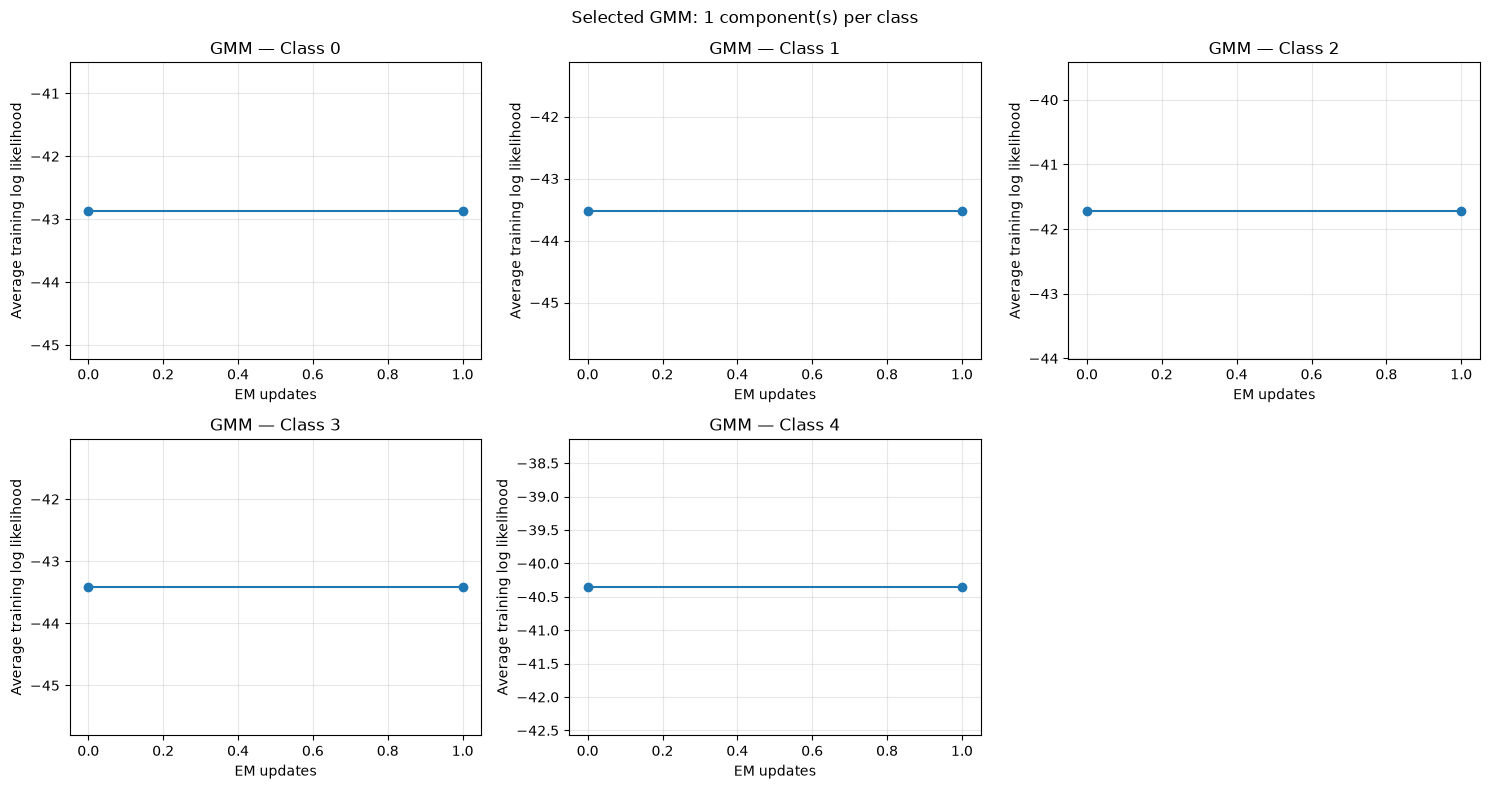

In [82]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, class_label, model in zip(
    axes.flat,
    best_gmm_model.classes_,
    best_gmm_model.models_
):
    history = model.log_likelihood_history_

    ax.plot(
        range(len(history)),
        history,
        marker="o"
    )

    ax.set_title(f"GMM — Class {class_label}")
    ax.set_xlabel("EM updates")
    ax.set_ylabel("Average training log likelihood")
    ax.grid(alpha=0.3)

# Hide any unused subplot.
for ax in axes.flat[len(best_gmm_model.classes_):]:
    ax.set_visible(False)

plt.suptitle(
    f"Selected GMM: {best_components} component(s) per class"
)

plt.tight_layout()
plt.show()

In [83]:
#SVM
from scipy.optimize import minimize


def svm_objective_and_gradient(parameters, X, y_signed, C):
    weights = parameters[:-1]
    intercept = parameters[-1]

    scores = X @ weights + intercept

    hinge = np.maximum(
        0.0,
        1.0 - y_signed * scores
    )

    objective = (
        0.5 * np.dot(weights, weights)
        + C * np.mean(hinge ** 2)
    )

    score_gradient = (
        -2.0 * C * y_signed * hinge / len(y_signed)
    )

    weight_gradient = (
        weights + X.T @ score_gradient
    )

    intercept_gradient = np.sum(score_gradient)

    gradient = np.concatenate([
        weight_gradient,
        [intercept_gradient]
    ])

    return objective, gradient

In [84]:
class ManualBinaryLinearSVM:
    def __init__(self, C=1.0, max_iter=2000):
        self.C = C
        self.max_iter = max_iter

    def fit(self, X, y_signed):
        X = np.asarray(X, dtype=float)
        y_signed = np.asarray(y_signed, dtype=float)

        if not np.array_equal(
            np.unique(y_signed),
            np.array([-1.0, 1.0])
        ):
            raise ValueError(
                "Binary SVM requires both -1 and +1 labels."
            )

        # Deterministic initialization.
        initial_parameters = np.zeros(X.shape[1] + 1)

        self.optimization_result_ = minimize(
            fun=svm_objective_and_gradient,
            x0=initial_parameters,
            args=(X, y_signed, self.C),
            method="L-BFGS-B",
            jac=True,
            options={
                "maxiter": self.max_iter,
                "ftol": 1e-12,
                "gtol": 1e-6
            }
        )

        self.weights_ = (
            self.optimization_result_.x[:-1]
        )

        self.intercept_ = (
            self.optimization_result_.x[-1]
        )

        self.converged_ = bool(
            self.optimization_result_.success
        )

        self.n_iter_ = self.optimization_result_.nit

        return self

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)

        return X @ self.weights_ + self.intercept_


class ManualLinearSVM:
    """Multiclass linear SVM using one-versus-rest."""

    def __init__(self, C=1.0, max_iter=2000):
        self.C = C
        self.max_iter = max_iter

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        self.classes_ = np.unique(y)

        if len(self.classes_) < 2:
            raise ValueError(
                "SVM requires at least two classes."
            )

        self.models_ = []

        for class_label in self.classes_:
            # Current class: +1; all other classes: -1.
            binary_labels = np.where(
                y == class_label,
                1.0,
                -1.0
            )

            model = ManualBinaryLinearSVM(
                C=self.C,
                max_iter=self.max_iter
            )

            model.fit(X, binary_labels)
            self.models_.append(model)

        self.converged_ = all(
            model.converged_
            for model in self.models_
        )

        return self

    def decision_function(self, X):
        return np.column_stack([
            model.decision_function(X)
            for model in self.models_
        ])

    def predict(self, X):
        scores = self.decision_function(X)

        predicted_indices = np.argmax(
            scores,
            axis=1
        )

        return self.classes_[predicted_indices]

In [85]:
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]

svm_models = {}
svm_val_predictions = {}
svm_rows = []

for C in C_values:
    print(
        f"Training multiclass linear SVM with C={C}...",
        flush=True
    )

    model = ManualLinearSVM(
        C=C,
        max_iter=2000
    )

    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_val_scaled)

    accuracy = accuracy_score_manual(
        y_val,
        predictions
    )

    svm_models[C] = model
    svm_val_predictions[C] = predictions

    row = {
        "C": C,
        "Validation accuracy (%)": 100 * accuracy,
        "All classes converged": model.converged_
    }

    for class_label, binary_model in zip(
        model.classes_,
        model.models_
    ):
        row[f"Class {class_label} iterations"] = (
            binary_model.n_iter_
        )

        if not binary_model.converged_:
            print(
                f"  Class {class_label}: "
                f"{binary_model.optimization_result_.message}"
            )

    svm_rows.append(row)

svm_validation_table = pd.DataFrame(svm_rows)

print("\nLinear SVM validation comparison:")
print(
    svm_validation_table.round(3).to_string(index=False)
)

eligible_svm_candidates = svm_validation_table[
    svm_validation_table["All classes converged"]
].copy()

if eligible_svm_candidates.empty:
    raise RuntimeError(
        "No SVM candidate fully converged. "
        "Inspect the optimizer messages."
    )

# Highest accuracy first; smaller C wins a tie.
ranked_svm_candidates = eligible_svm_candidates.sort_values(
    by=["Validation accuracy (%)", "C"],
    ascending=[False, True]
)

best_C = float(
    ranked_svm_candidates.iloc[0]["C"]
)

best_svm_model = svm_models[best_C]

print(f"\nSelected C: {best_C}\n")

best_svm_val_accuracy = show_evaluation(
    f"Linear SVM, one-versus-rest (C={best_C})",
    y_val,
    svm_val_predictions[best_C]
)

Training multiclass linear SVM with C=0.01...
Training multiclass linear SVM with C=0.1...
Training multiclass linear SVM with C=1.0...
Training multiclass linear SVM with C=10.0...
Training multiclass linear SVM with C=100.0...

Linear SVM validation comparison:
     C  Validation accuracy (%)  All classes converged  Class 0 iterations  Class 1 iterations  Class 2 iterations  Class 3 iterations  Class 4 iterations
  0.01                     42.6                   True                   7                   7                   9                   7                   8
  0.10                     46.0                   True                   9                   8                   9                   9                   8
  1.00                     50.0                   True                  13                  14                  15                  14                  15
 10.00                     51.2                   True                  23                  24                  23  

Original 36 features — validation comparison:
Classifier                  Setting  Validation accuracy (%)
       LDA        Shared covariance                     52.8
       KNN                     k=11                     54.0
       GMM 1 component(s) per class                     54.6
Linear SVM One-versus-rest, C=100.0                     51.6


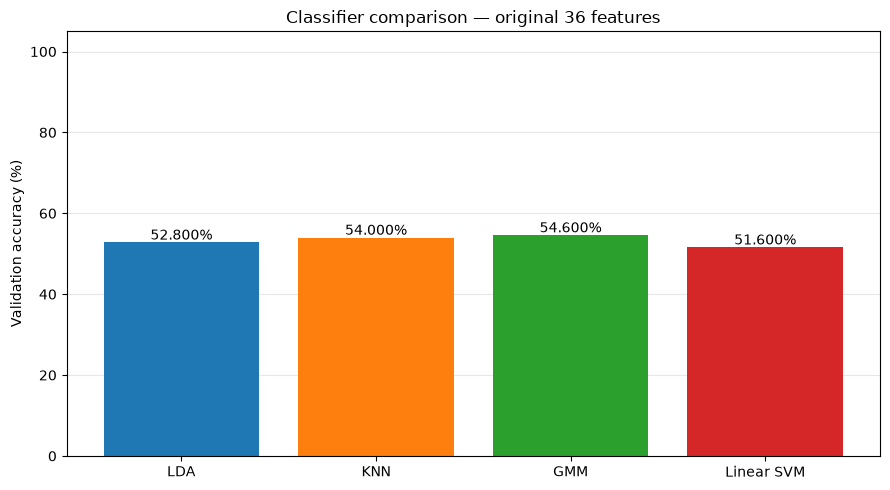

In [86]:
validation_results = [
    {
        "Classifier": "LDA",
        "Setting": "Shared covariance",
        "Validation accuracy (%)": 100 * lda_val_accuracy
    },
    {
        "Classifier": "KNN",
        "Setting": f"k={best_k}",
        "Validation accuracy (%)": (
            100 * best_knn_val_accuracy
        )
    },
    {
        "Classifier": "GMM",
        "Setting": (
            f"{best_components} component(s) per class"
        ),
        "Validation accuracy (%)": (
            100 * best_gmm_val_accuracy
        )
    },
    {
        "Classifier": "Linear SVM",
        "Setting": f"One-versus-rest, C={best_C}",
        "Validation accuracy (%)": (
            100 * best_svm_val_accuracy
        )
    }
]

validation_comparison = pd.DataFrame(
    validation_results
)

print("Original 36 features — validation comparison:")
print(
    validation_comparison.to_string(index=False)
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    validation_comparison["Classifier"],
    validation_comparison["Validation accuracy (%)"],
    color=[
        "tab:blue",
        "tab:orange",
        "tab:green",
        "tab:red"
    ]
)

for bar, accuracy in zip(
    bars,
    validation_comparison["Validation accuracy (%)"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 0.7,
        f"{accuracy:.3f}%",
        ha="center"
    )

ax.set_ylim(0, 105)
ax.set_ylabel("Validation accuracy (%)")
ax.set_title("Classifier comparison — original 36 features")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [87]:
#PCA
class ManualPCA:
    def fit(self, X):
        X = np.asarray(X, dtype=float)

        self.mean_ = X.mean(axis=0)
        centered = X - self.mean_

        covariance = (
            centered.T @ centered
        ) / (len(X) - 1)

        eigenvalues, eigenvectors = np.linalg.eigh(
            covariance
        )

        # Sort principal components by decreasing variance.
        order = np.argsort(eigenvalues)[::-1]

        self.eigenvalues_ = np.maximum(
            eigenvalues[order],
            0.0
        )

        # Each column represents a principal direction.
        self.components_ = eigenvectors[:, order]

        total_variance = self.eigenvalues_.sum()

        if total_variance <= 0:
            raise ValueError(
                "PCA requires nonzero training variance."
            )

        self.explained_variance_ratio_ = (
            self.eigenvalues_ / total_variance
        )

        self.cumulative_variance_ = np.cumsum(
            self.explained_variance_ratio_
        )

        return self

    def transform(self, X, n_components):
        X = np.asarray(X, dtype=float)

        if X.shape[1] != len(self.mean_):
            raise ValueError(
                "Input feature count differs from PCA training data."
            )

        if not 1 <= n_components <= self.components_.shape[1]:
            raise ValueError(
                "Invalid number of PCA components."
            )

        centered = X - self.mean_

        return centered @ self.components_[:, :n_components]

 Principal component  Explained variance (%)  Cumulative variance (%)
                   1                  15.186                   15.186
                   2                   9.744                   24.930
                   3                   7.447                   32.378
                   4                   6.256                   38.633
                   5                   5.623                   44.256
                   6                   5.471                   49.728
                   7                   4.663                   54.390
                   8                   3.911                   58.301
                   9                   3.698                   62.000
                  10                   3.490                   65.490
                  11                   2.762                   68.252
                  12                   2.550                   70.802
                  13                   1.931                   72.733
                  14

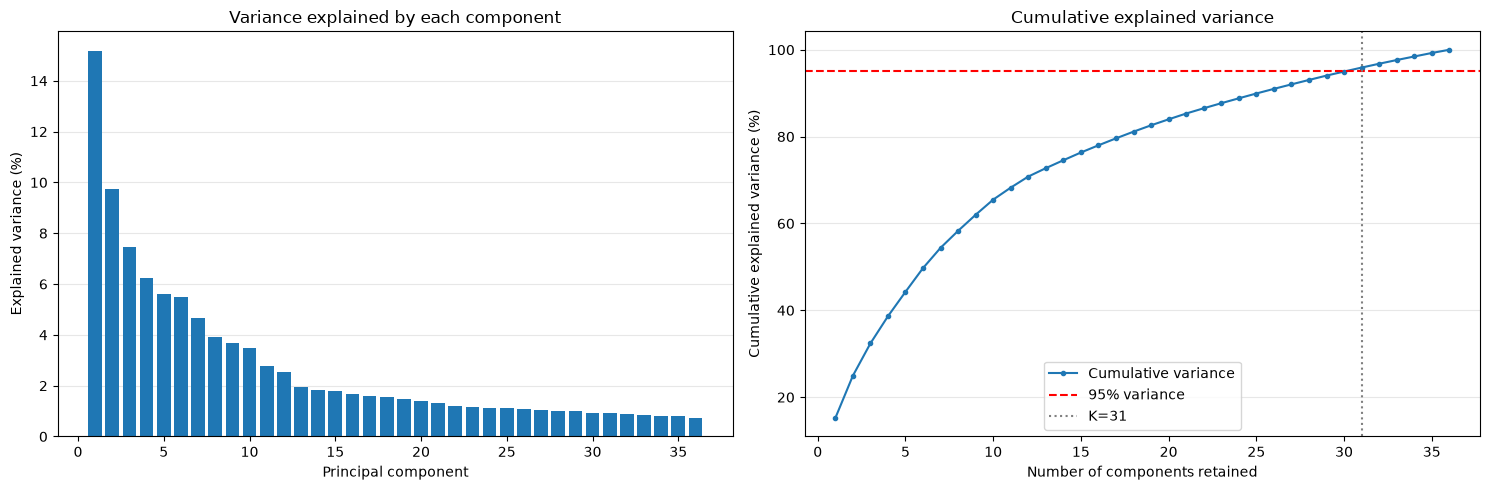

In [88]:
# Fit PCA using standardized training data only.
pca_model = ManualPCA()
pca_model.fit(X_train_scaled)

component_numbers = np.arange(1, n_features + 1)

pca_variance_table = pd.DataFrame({
    "Principal component": component_numbers,
    "Explained variance (%)": (
        100 * pca_model.explained_variance_ratio_
    ),
    "Cumulative variance (%)": (
        100 * pca_model.cumulative_variance_
    )
})

print(
    pca_variance_table.round(3).to_string(index=False)
)

# Small tolerance avoids floating-point issues at the threshold.
K_95 = int(
    np.flatnonzero(
        pca_model.cumulative_variance_ >= 0.95 - 1e-12
    )[0] + 1
)

print(
    f"\nComponents needed to retain at least "
    f"95% training variance: {K_95}"
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(
    component_numbers,
    100 * pca_model.explained_variance_ratio_
)

axes[0].set_title("Variance explained by each component")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance (%)")

axes[1].plot(
    component_numbers,
    100 * pca_model.cumulative_variance_,
    marker=".",
    label="Cumulative variance"
)

axes[1].axhline(
    95,
    color="red",
    linestyle="--",
    label="95% variance"
)

axes[1].axvline(
    K_95,
    color="gray",
    linestyle=":",
    label=f"K={K_95}"
)

axes[1].set_title("Cumulative explained variance")
axes[1].set_xlabel("Number of components retained")
axes[1].set_ylabel("Cumulative explained variance (%)")
axes[1].legend()

for ax in axes:
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [89]:
class_colors = {
    label: plt.get_cmap("tab10")(i)
    for i, label in enumerate(class_labels)
}

 K Training shape Validation shape  Retained variance (%)
 1      (2000, 1)         (500, 1)                 15.186
 2      (2000, 2)         (500, 2)                 24.930
 4      (2000, 4)         (500, 4)                 38.633
 8      (2000, 8)         (500, 8)                 58.301
12     (2000, 12)        (500, 12)                 70.802
16     (2000, 16)        (500, 16)                 77.995
24     (2000, 24)        (500, 24)                 88.817
30     (2000, 30)        (500, 30)                 94.978
36     (2000, 36)        (500, 36)                100.000


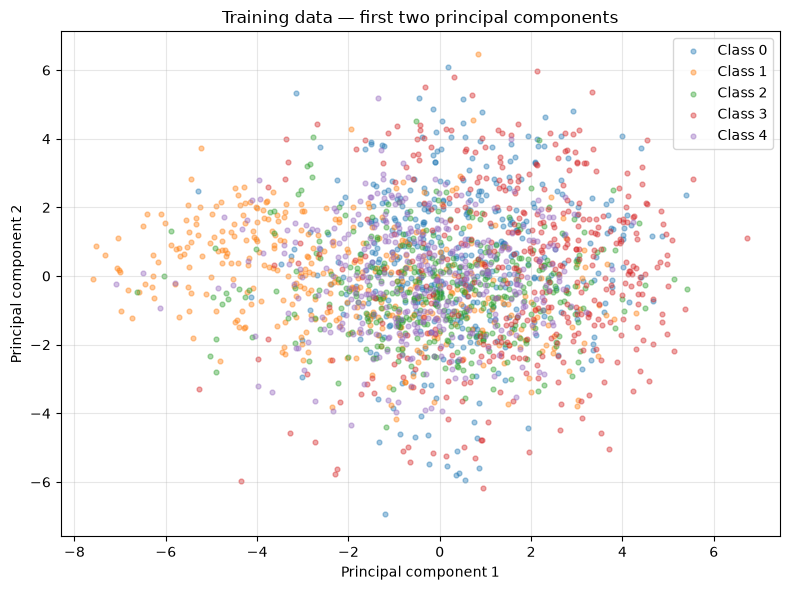

In [90]:
K_values = [1, 2, 4, 8, 12, 16, 24, 30, 36]

X_train_pca_all = pca_model.transform(
    X_train_scaled,
    n_components=n_features
)

X_val_pca_all = pca_model.transform(
    X_val_scaled,
    n_components=n_features
)

projection_rows = []

for K in K_values:
    projection_rows.append({
        "K": K,
        "Training shape": str(
            X_train_pca_all[:, :K].shape
        ),
        "Validation shape": str(
            X_val_pca_all[:, :K].shape
        ),
        "Retained variance (%)": (
            100 * pca_model.cumulative_variance_[K - 1]
        )
    })

print(
    pd.DataFrame(projection_rows)
    .round(3)
    .to_string(index=False)
)

# Visualize training samples in the first two PCA dimensions.
fig, ax = plt.subplots(figsize=(8, 6))

for class_label in class_labels:
    mask = y_train == class_label

    ax.scatter(
        X_train_pca_all[mask, 0],
        X_train_pca_all[mask, 1],
        s=12,
        alpha=0.4,
        color=class_colors[class_label],
        label=f"Class {class_label}"
    )

ax.set_xlabel("Principal component 1")
ax.set_ylabel("Principal component 2")
ax.set_title("Training data — first two principal components")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [91]:
neighbor_values = [3, 5, 7, 11]
component_values = [1, 2, 3, 4]
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]

pca_results = []
pca_selected_models = {}
pca_tuning_rows = []

for K in K_values:
    print(f"\nProcessing PCA K={K}...", flush=True)

    train_features = X_train_pca_all[:, :K]
    val_features = X_val_pca_all[:, :K]

    # --------------------------------------------------
    # 1. LDA
    # --------------------------------------------------
    lda = LDA(regularization=1e-6)
    lda.fit(train_features, y_train)

    lda_predictions = lda.predict(val_features)

    lda_accuracy = accuracy_score_manual(
        y_val,
        lda_predictions
    )

    # --------------------------------------------------
    # 2. KNN
    # --------------------------------------------------
    knn = KNN(batch_size=128)
    knn.fit(train_features, y_train)

    knn_predictions = knn.predict_for_k_values(
        val_features,
        neighbor_values
    )

    knn_accuracies = {}

    for neighbours in neighbor_values:
        accuracy = accuracy_score_manual(
            y_val,
            knn_predictions[neighbours]
        )

        knn_accuracies[neighbours] = accuracy

        pca_tuning_rows.append({
            "K": K,
            "Classifier": "KNN",
            "Setting": f"k={neighbours}",
            "Validation accuracy (%)": 100 * accuracy,
            "Status": "OK"
        })

    # Smaller neighbour count wins an accuracy tie.
    selected_neighbours = max(
        sorted(knn_accuracies),
        key=lambda k: knn_accuracies[k]
    )

    knn_accuracy = knn_accuracies[selected_neighbours]

    # --------------------------------------------------
    # 3. GMM
    # --------------------------------------------------
    selected_gmm = None
    selected_components = None
    gmm_accuracy = -np.inf

    for components in component_values:
        gmm = GMMClassifier(
            n_components=components,
            max_iter=300,
            tol=1e-5,
            regularization=1e-4
        )

        try:
            gmm.fit(train_features, y_train)

            predictions = gmm.predict(val_features)

            accuracy = accuracy_score_manual(
                y_val,
                predictions
            )

            converged = all(
                model.converged_
                for model in gmm.models_
            )

            pca_tuning_rows.append({
                "K": K,
                "Classifier": "GMM",
                "Setting": f"components={components}",
                "Validation accuracy (%)": 100 * accuracy,
                "Status": (
                    "OK" if converged else "Iteration limit"
                )
            })

            if not converged:
                print(
                    f"  GMM components={components}: "
                    "not all class models converged; excluded.",
                    flush=True
                )

            # Smaller component count wins an accuracy tie.
            if converged and accuracy > gmm_accuracy:
                selected_gmm = gmm
                selected_components = components
                gmm_accuracy = accuracy

        except (ValueError, np.linalg.LinAlgError) as error:
            print(
                f"  GMM components={components} failed: {error}",
                flush=True
            )

            pca_tuning_rows.append({
                "K": K,
                "Classifier": "GMM",
                "Setting": f"components={components}",
                "Validation accuracy (%)": np.nan,
                "Status": str(error)
            })

    if selected_gmm is None:
        raise RuntimeError(
            f"No GMM candidate fully converged for K={K}. "
            "Inspect the diagnostics before continuing."
        )

    # --------------------------------------------------
    # 4. Multiclass linear SVM
    # --------------------------------------------------
    selected_svm = None
    selected_C = None
    svm_accuracy = -np.inf

    for C in C_values:
        svm = ManualLinearSVM(
            C=C,
            max_iter=2000
        )

        svm.fit(train_features, y_train)

        predictions = svm.predict(val_features)

        accuracy = accuracy_score_manual(
            y_val,
            predictions
        )

        pca_tuning_rows.append({
            "K": K,
            "Classifier": "Linear SVM",
            "Setting": f"C={C}",
            "Validation accuracy (%)": 100 * accuracy,
            "Status": (
                "OK" if svm.converged_ else "Not converged"
            )
        })

        if not svm.converged_:
            print(
                f"  SVM C={C}: not all binary models "
                "converged; excluded.",
                flush=True
            )

        # Smaller C wins an accuracy tie.
        if svm.converged_ and accuracy > svm_accuracy:
            selected_svm = svm
            selected_C = C
            svm_accuracy = accuracy

    if selected_svm is None:
        raise RuntimeError(
            f"No SVM candidate fully converged for K={K}."
        )

    # --------------------------------------------------
    # Store selected models and settings
    # --------------------------------------------------
    pca_selected_models[K] = {
        "LDA": lda,
        "KNN": knn,
        "KNN neighbours": selected_neighbours,
        "GMM": selected_gmm,
        "GMM components": selected_components,
        "Linear SVM": selected_svm,
        "SVM C": selected_C
    }

    pca_results.append({
        "K": K,
        "Retained variance (%)": (
            100 * pca_model.cumulative_variance_[K - 1]
        ),
        "LDA": 100 * lda_accuracy,
        "KNN": 100 * knn_accuracy,
        "GMM": 100 * gmm_accuracy,
        "Linear SVM": 100 * svm_accuracy,
        "KNN neighbours": selected_neighbours,
        "GMM components": selected_components,
        "SVM C": selected_C
    })

    print(
        f"Completed K={K}: "
        f"LDA={100 * lda_accuracy:.3f}%, "
        f"KNN={100 * knn_accuracy:.3f}%, "
        f"GMM={100 * gmm_accuracy:.3f}%, "
        f"SVM={100 * svm_accuracy:.3f}%",
        flush=True
    )

pca_results_table = pd.DataFrame(pca_results)
pca_tuning_table = pd.DataFrame(pca_tuning_rows)

print("\nPCA validation results:")
print(
    pca_results_table.round(3).to_string(index=False)
)


Processing PCA K=1...


Completed K=1: LDA=34.600%, KNN=29.200%, GMM=36.800%, SVM=30.400%

Processing PCA K=2...
Completed K=2: LDA=38.800%, KNN=34.000%, GMM=40.600%, SVM=33.200%

Processing PCA K=4...
Completed K=4: LDA=42.600%, KNN=45.600%, GMM=47.400%, SVM=41.400%

Processing PCA K=8...
Completed K=8: LDA=45.800%, KNN=50.000%, GMM=50.400%, SVM=43.600%

Processing PCA K=12...
Completed K=12: LDA=46.800%, KNN=52.200%, GMM=52.800%, SVM=45.000%

Processing PCA K=16...
Completed K=16: LDA=49.600%, KNN=54.400%, GMM=53.800%, SVM=46.400%

Processing PCA K=24...
Completed K=24: LDA=51.400%, KNN=53.000%, GMM=54.400%, SVM=50.200%

Processing PCA K=30...
Completed K=30: LDA=51.800%, KNN=53.400%, GMM=55.600%, SVM=50.800%

Processing PCA K=36...
Completed K=36: LDA=52.800%, KNN=54.000%, GMM=54.600%, SVM=51.600%

PCA validation results:
 K  Retained variance (%)  LDA  KNN  GMM  Linear SVM  KNN neighbours  GMM components  SVM C
 1                 15.186 34.6 29.2 36.8        30.4               7               1    1.0
 2 

Validation accuracy comparison (%):
      Representation  LDA  KNN  GMM  Linear SVM
Original 36 features 52.8 54.0 54.6        51.6
             PCA K=1 34.6 29.2 36.8        30.4
             PCA K=2 38.8 34.0 40.6        33.2
             PCA K=4 42.6 45.6 47.4        41.4
             PCA K=8 45.8 50.0 50.4        43.6
            PCA K=12 46.8 52.2 52.8        45.0
            PCA K=16 49.6 54.4 53.8        46.4
            PCA K=24 51.4 53.0 54.4        50.2
            PCA K=30 51.8 53.4 55.6        50.8
            PCA K=36 52.8 54.0 54.6        51.6


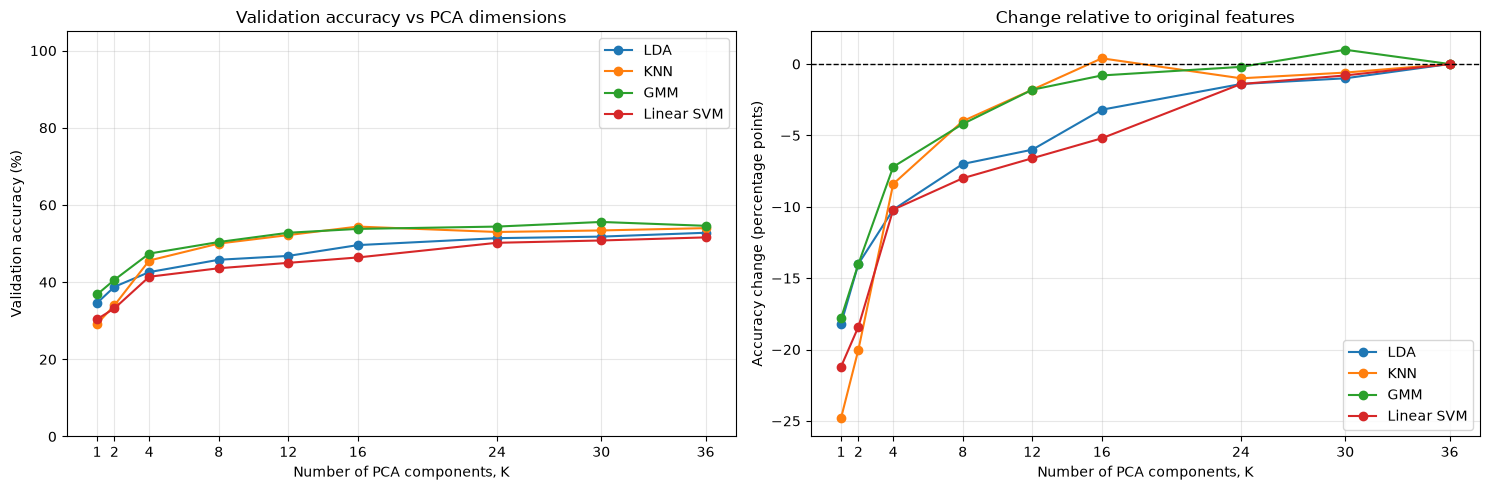

In [92]:
classifier_names = [
    "LDA", "KNN", "GMM", "Linear SVM"
]

original_accuracies = dict(zip(
    validation_comparison["Classifier"],
    validation_comparison["Validation accuracy (%)"]
))

comparison_rows = [{
    "Representation": f"Original {n_features} features",
    **{
        classifier: original_accuracies[classifier]
        for classifier in classifier_names
    }
}]

for _, row in pca_results_table.iterrows():
    comparison_rows.append({
        "Representation": f"PCA K={int(row['K'])}",
        **{
            classifier: row[classifier]
            for classifier in classifier_names
        }
    })

original_vs_pca_table = pd.DataFrame(
    comparison_rows
)

print("Validation accuracy comparison (%):")
print(
    original_vs_pca_table.round(3).to_string(index=False)
)

colors = {
    "LDA": "tab:blue",
    "KNN": "tab:orange",
    "GMM": "tab:green",
    "Linear SVM": "tab:red"
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for classifier in classifier_names:
    axes[0].plot(
        pca_results_table["K"],
        pca_results_table[classifier],
        marker="o",
        color=colors[classifier],
        label=classifier
    )

    axes[1].plot(
        pca_results_table["K"],
        (
            pca_results_table[classifier]
            - original_accuracies[classifier]
        ),
        marker="o",
        color=colors[classifier],
        label=classifier
    )

axes[0].set_title("Validation accuracy vs PCA dimensions")
axes[0].set_ylabel("Validation accuracy (%)")
axes[0].set_ylim(0, 105)

axes[1].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[1].set_title("Change relative to original features")
axes[1].set_ylabel("Accuracy change (percentage points)")

for ax in axes:
    ax.set_xlabel("Number of PCA components, K")
    ax.set_xticks(K_values)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [93]:
classifier_names = ["LDA", "KNN", "GMM", "Linear SVM"]

original_test_predictions = {
    "LDA": lda_model.predict(X_test_scaled),

    "KNN": knn_model.predict_for_k_values(
        X_test_scaled,
        [best_k]
    )[best_k],

    "GMM": best_gmm_model.predict(X_test_scaled),

    "Linear SVM": best_svm_model.predict(X_test_scaled)
}

original_settings = {
    "LDA": "Shared covariance",
    "KNN": f"k={best_k}",
    "GMM": f"{best_components} component(s) per class",
    "Linear SVM": f"One-versus-rest, C={best_C}"
}

original_test_rows = []

for classifier in classifier_names:
    predictions = original_test_predictions[classifier]

    correct = int(np.sum(predictions == y_test))
    errors = len(y_test) - correct

    original_test_rows.append({
        "Classifier": classifier,
        "Setting": original_settings[classifier],
        "Correct": correct,
        "Errors": errors,
        "Test accuracy (%)": 100 * correct / len(y_test)
    })

original_test_table = pd.DataFrame(original_test_rows)

print(f"Original {n_features} features — final test results:")
print(
    original_test_table.round(3).to_string(index=False)
)

Original 36 features — final test results:
Classifier                  Setting  Correct  Errors  Test accuracy (%)
       LDA        Shared covariance      245     255               49.0
       KNN                     k=11      245     255               49.0
       GMM 1 component(s) per class      254     246               50.8
Linear SVM One-versus-rest, C=100.0      250     250               50.0


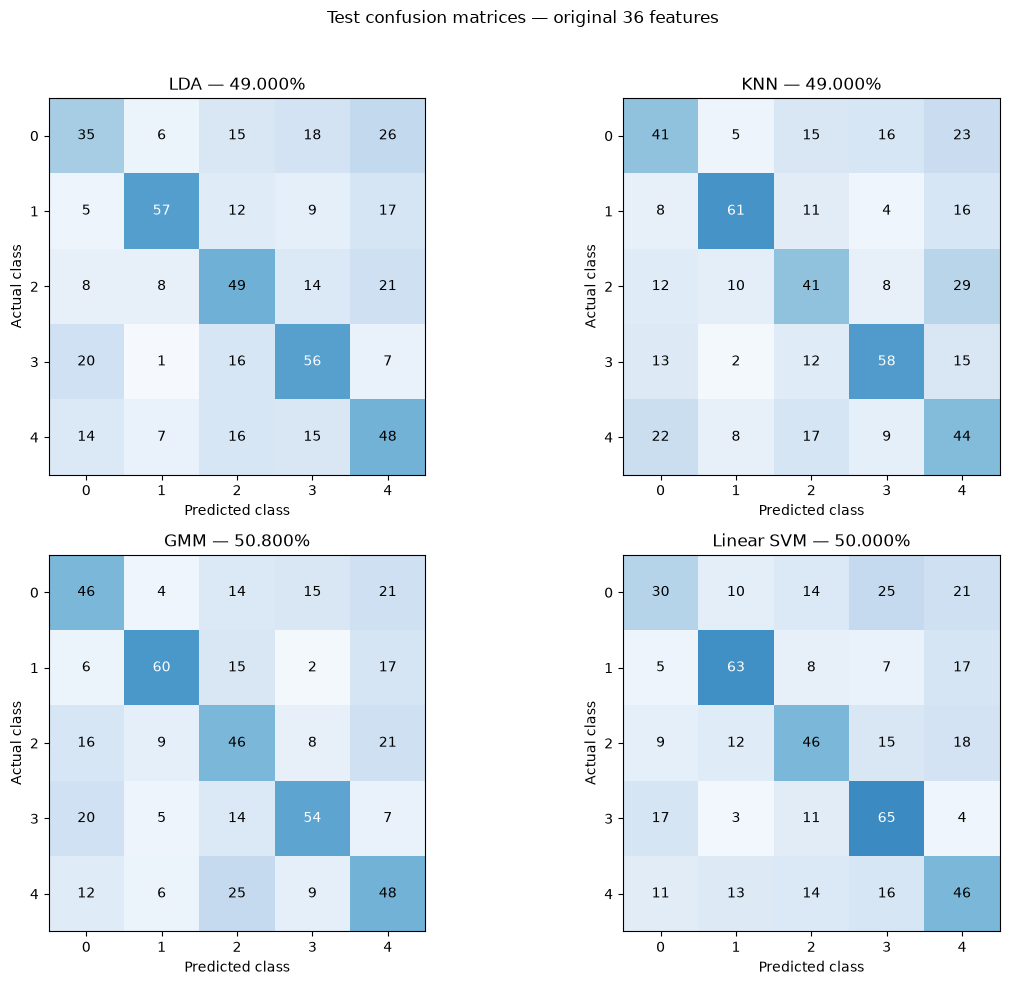

In [94]:
def plot_confusion_matrix_manual(
    ax,
    y_true,
    y_pred,
    title
):
    matrix = confusion_matrix_manual(y_true, y_pred)

    # Largest actual-class count determines the colour scale.
    color_max = max(1, int(matrix.sum(axis=1).max()))

    ax.imshow(
        matrix,
        cmap="Blues",
        vmin=0,
        vmax=color_max
    )

    for row in range(len(class_labels)):
        for column in range(len(class_labels)):
            value = matrix[row, column]

            ax.text(
                column,
                row,
                str(value),
                ha="center",
                va="center",
                color=(
                    "white"
                    if value > color_max / 2
                    else "black"
                ),
                fontsize=10
            )

    positions = np.arange(len(class_labels))

    ax.set_xticks(positions)
    ax.set_yticks(positions)
    ax.set_xticklabels(class_labels)
    ax.set_yticklabels(class_labels)

    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.set_title(title)


fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, classifier in zip(
    axes.flat,
    classifier_names
):
    predictions = original_test_predictions[classifier]

    accuracy = 100 * accuracy_score_manual(
        y_test,
        predictions
    )

    plot_confusion_matrix_manual(
        ax,
        y_test,
        predictions,
        f"{classifier} — {accuracy:.3f}%"
    )

fig.suptitle(
    f"Test confusion matrices — original {n_features} features"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [95]:
def classification_metrics_manual(y_true, y_pred):
    matrix = confusion_matrix_manual(y_true, y_pred)
    rows = []

    for index, class_label in enumerate(class_labels):
        true_positive = matrix[index, index]

        false_positive = (
            matrix[:, index].sum() - true_positive
        )

        false_negative = (
            matrix[index, :].sum() - true_positive
        )

        precision_denominator = (
            true_positive + false_positive
        )

        recall_denominator = (
            true_positive + false_negative
        )

        precision = (
            true_positive / precision_denominator
            if precision_denominator > 0 else 0.0
        )

        recall = (
            true_positive / recall_denominator
            if recall_denominator > 0 else 0.0
        )

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall > 0 else 0.0
        )

        rows.append({
            "Class": class_label,
            "Precision": precision,
            "Recall": recall,
            "F1-score": f1,
            "Support": int(matrix[index, :].sum())
        })

    return rows


metric_rows = []
macro_rows = []

for classifier in classifier_names:
    class_metrics = classification_metrics_manual(
        y_test,
        original_test_predictions[classifier]
    )

    for row in class_metrics:
        metric_rows.append({
            "Classifier": classifier,
            **row
        })

    macro_rows.append({
        "Classifier": classifier,
        "Macro precision": np.mean([
            row["Precision"] for row in class_metrics
        ]),
        "Macro recall": np.mean([
            row["Recall"] for row in class_metrics
        ]),
        "Macro F1": np.mean([
            row["F1-score"] for row in class_metrics
        ])
    })

original_test_metrics = pd.DataFrame(metric_rows)
original_macro_metrics = pd.DataFrame(macro_rows)

print("Original-feature test metrics by class:")
print(
    original_test_metrics.round(4).to_string(index=False)
)

print("\nMacro-averaged test metrics:")
print(
    original_macro_metrics.round(4).to_string(index=False)
)

Original-feature test metrics by class:
Classifier  Class  Precision  Recall  F1-score  Support
       LDA      0     0.4268    0.35    0.3846      100
       LDA      1     0.7215    0.57    0.6369      100
       LDA      2     0.4537    0.49    0.4712      100
       LDA      3     0.5000    0.56    0.5283      100
       LDA      4     0.4034    0.48    0.4384      100
       KNN      0     0.4271    0.41    0.4184      100
       KNN      1     0.7093    0.61    0.6559      100
       KNN      2     0.4271    0.41    0.4184      100
       KNN      3     0.6105    0.58    0.5949      100
       KNN      4     0.3465    0.44    0.3877      100
       GMM      0     0.4600    0.46    0.4600      100
       GMM      1     0.7143    0.60    0.6522      100
       GMM      2     0.4035    0.46    0.4299      100
       GMM      3     0.6136    0.54    0.5745      100
       GMM      4     0.4211    0.48    0.4486      100
Linear SVM      0     0.4167    0.30    0.3488      100
Linear S

In [96]:
# Select reduced dimensions using VALIDATION accuracy only.
reduced_validation_results = pca_results_table[
    pca_results_table["K"] < n_features
].copy()

selected_reduced_K = {}

for classifier in classifier_names:
    ranked_candidates = reduced_validation_results.sort_values(
        by=[classifier, "K"],
        ascending=[False, True]
    )

    selected_reduced_K[classifier] = int(
        ranked_candidates.iloc[0]["K"]
    )

print("Reduced K selected using validation data:")
print(selected_reduced_K)

# Transform test data with the existing training-fitted PCA.
X_test_pca_all = pca_model.transform(
    X_test_scaled,
    n_components=n_features
)

pca_test_predictions = {}
pca_test_rows = []

for K in K_values:
    print(f"Testing PCA K={K}...", flush=True)

    test_features = X_test_pca_all[:, :K]
    selected = pca_selected_models[K]

    neighbours = selected["KNN neighbours"]

    predictions = {
        "LDA": selected["LDA"].predict(
            test_features
        ),

        "KNN": selected["KNN"].predict_for_k_values(
            test_features,
            [neighbours]
        )[neighbours],

        "GMM": selected["GMM"].predict(
            test_features
        ),

        "Linear SVM": selected["Linear SVM"].predict(
            test_features
        )
    }

    pca_test_predictions[K] = predictions

    result_row = {
        "K": K,
        "Retained training variance (%)": (
            100 * pca_model.cumulative_variance_[K - 1]
        )
    }

    for classifier in classifier_names:
        result_row[classifier] = (
            100 * accuracy_score_manual(
                y_test,
                predictions[classifier]
            )
        )

    pca_test_rows.append(result_row)

pca_test_table = pd.DataFrame(pca_test_rows)

print("\nPCA test accuracies (%):")
print(
    pca_test_table.round(3).to_string(index=False)
)

Reduced K selected using validation data:
{'LDA': 30, 'KNN': 16, 'GMM': 30, 'Linear SVM': 30}
Testing PCA K=1...
Testing PCA K=2...
Testing PCA K=4...
Testing PCA K=8...
Testing PCA K=12...
Testing PCA K=16...
Testing PCA K=24...
Testing PCA K=30...
Testing PCA K=36...

PCA test accuracies (%):
 K  Retained training variance (%)  LDA  KNN  GMM  Linear SVM
 1                          15.186 31.2 28.8 34.4        29.4
 2                          24.930 34.0 33.2 39.2        30.2
 4                          38.633 37.8 43.4 45.2        36.4
 8                          58.301 41.2 46.4 46.8        41.8
12                          70.802 44.0 49.2 50.0        42.6
16                          77.995 45.4 52.2 52.2        44.2
24                          88.817 48.0 50.8 52.6        47.0
30                          94.978 48.4 49.6 53.0        49.0
36                         100.000 49.0 49.0 50.8        50.0


Final comparison — TEST accuracy (%):
      Representation  LDA  KNN  GMM  Linear SVM
Original 36 features 49.0 49.0 50.8        50.0
             PCA K=1 31.2 28.8 34.4        29.4
             PCA K=2 34.0 33.2 39.2        30.2
             PCA K=4 37.8 43.4 45.2        36.4
             PCA K=8 41.2 46.4 46.8        41.8
            PCA K=12 44.0 49.2 50.0        42.6
            PCA K=16 45.4 52.2 52.2        44.2
            PCA K=24 48.0 50.8 52.6        47.0
            PCA K=30 48.4 49.6 53.0        49.0
            PCA K=36 49.0 49.0 50.8        50.0

Validation-selected reduced PCA models:
Classifier  Reduced K chosen on validation  Dimensions removed (%)  Original test accuracy (%)  Reduced PCA test accuracy (%)  Change (percentage points)
       LDA                              30                  16.667                        49.0                           48.4                        -0.6
       KNN                              16                  55.556                   

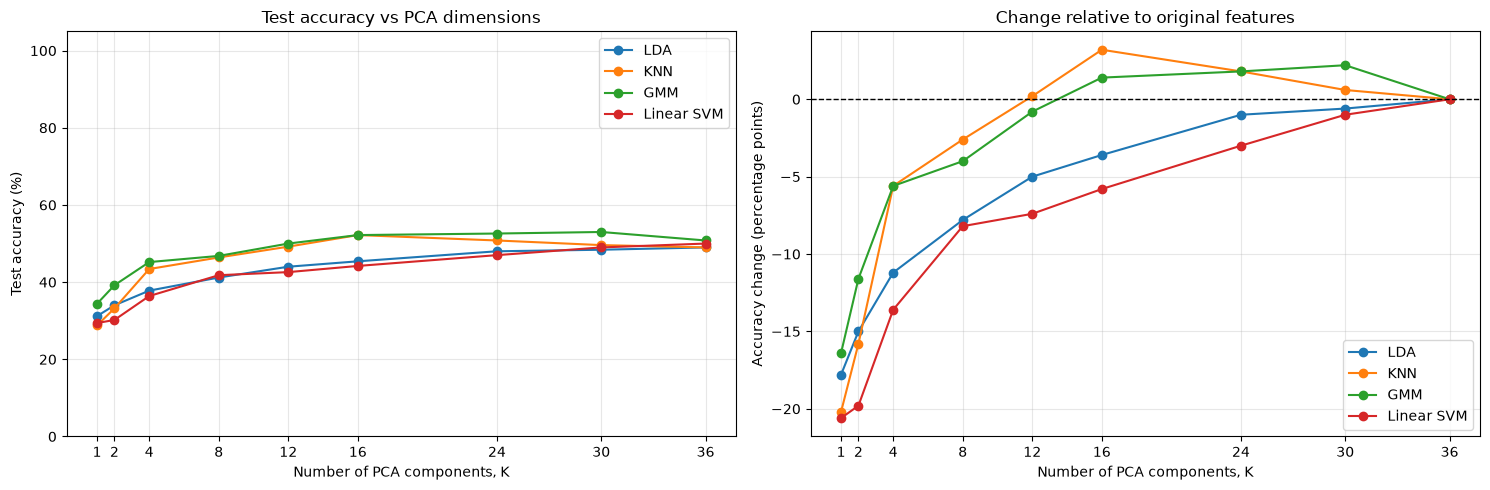

In [97]:
original_test_accuracies = dict(zip(
    original_test_table["Classifier"],
    original_test_table["Test accuracy (%)"]
))

# --------------------------------------------------
# A. Compare all representations
# --------------------------------------------------
final_rows = [{
    "Representation": f"Original {n_features} features",
    **{
        classifier: original_test_accuracies[classifier]
        for classifier in classifier_names
    }
}]

for _, row in pca_test_table.iterrows():
    final_rows.append({
        "Representation": f"PCA K={int(row['K'])}",
        **{
            classifier: row[classifier]
            for classifier in classifier_names
        }
    })

final_test_comparison = pd.DataFrame(final_rows)

print("Final comparison — TEST accuracy (%):")
print(
    final_test_comparison.round(3).to_string(index=False)
)

# --------------------------------------------------
# B. Summarize validation-selected reduced models
# --------------------------------------------------
reduced_summary_rows = []

for classifier in classifier_names:
    K = selected_reduced_K[classifier]

    selected_test_row = pca_test_table[
        pca_test_table["K"] == K
    ].iloc[0]

    reduced_accuracy = float(
        selected_test_row[classifier]
    )

    reduced_summary_rows.append({
        "Classifier": classifier,
        "Reduced K chosen on validation": K,
        "Dimensions removed (%)": (
            100 * (n_features - K) / n_features
        ),
        "Original test accuracy (%)": (
            original_test_accuracies[classifier]
        ),
        "Reduced PCA test accuracy (%)": reduced_accuracy,
        "Change (percentage points)": (
            reduced_accuracy
            - original_test_accuracies[classifier]
        )
    })

reduced_pca_summary = pd.DataFrame(
    reduced_summary_rows
)

print("\nValidation-selected reduced PCA models:")
print(
    reduced_pca_summary.round(3).to_string(index=False)
)

# --------------------------------------------------
# C. Plot test accuracy against PCA dimensions
# --------------------------------------------------
colors = {
    "LDA": "tab:blue",
    "KNN": "tab:orange",
    "GMM": "tab:green",
    "Linear SVM": "tab:red"
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for classifier in classifier_names:
    axes[0].plot(
        pca_test_table["K"],
        pca_test_table[classifier],
        marker="o",
        color=colors[classifier],
        label=classifier
    )

    axes[1].plot(
        pca_test_table["K"],
        (
            pca_test_table[classifier]
            - original_test_accuracies[classifier]
        ),
        marker="o",
        color=colors[classifier],
        label=classifier
    )

axes[0].set_title("Test accuracy vs PCA dimensions")
axes[0].set_ylabel("Test accuracy (%)")
axes[0].set_ylim(0, 105)

axes[1].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[1].set_title("Change relative to original features")
axes[1].set_ylabel("Accuracy change (percentage points)")

for ax in axes:
    ax.set_xlabel("Number of PCA components, K")
    ax.set_xticks(K_values)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [98]:
# Compare validation and test accuracy for original features.
validation_accuracy_lookup = dict(zip(
    validation_comparison["Classifier"],
    validation_comparison["Validation accuracy (%)"]
))

validation_test_rows = []

for classifier in classifier_names:
    validation_accuracy = validation_accuracy_lookup[classifier]
    test_accuracy = original_test_accuracies[classifier]

    validation_test_rows.append({
        "Classifier": classifier,
        "Validation accuracy (%)": validation_accuracy,
        "Test accuracy (%)": test_accuracy,
        "Test minus validation (percentage points)": (
            test_accuracy - validation_accuracy
        )
    })

validation_test_comparison = pd.DataFrame(
    validation_test_rows
)

print("Original features — validation versus test:")
print(
    validation_test_comparison.round(3).to_string(index=False)
)

Original features — validation versus test:
Classifier  Validation accuracy (%)  Test accuracy (%)  Test minus validation (percentage points)
       LDA                     52.8               49.0                                       -3.8
       KNN                     54.0               49.0                                       -5.0
       GMM                     54.6               50.8                                       -3.8
Linear SVM                     51.6               50.0                                       -1.6


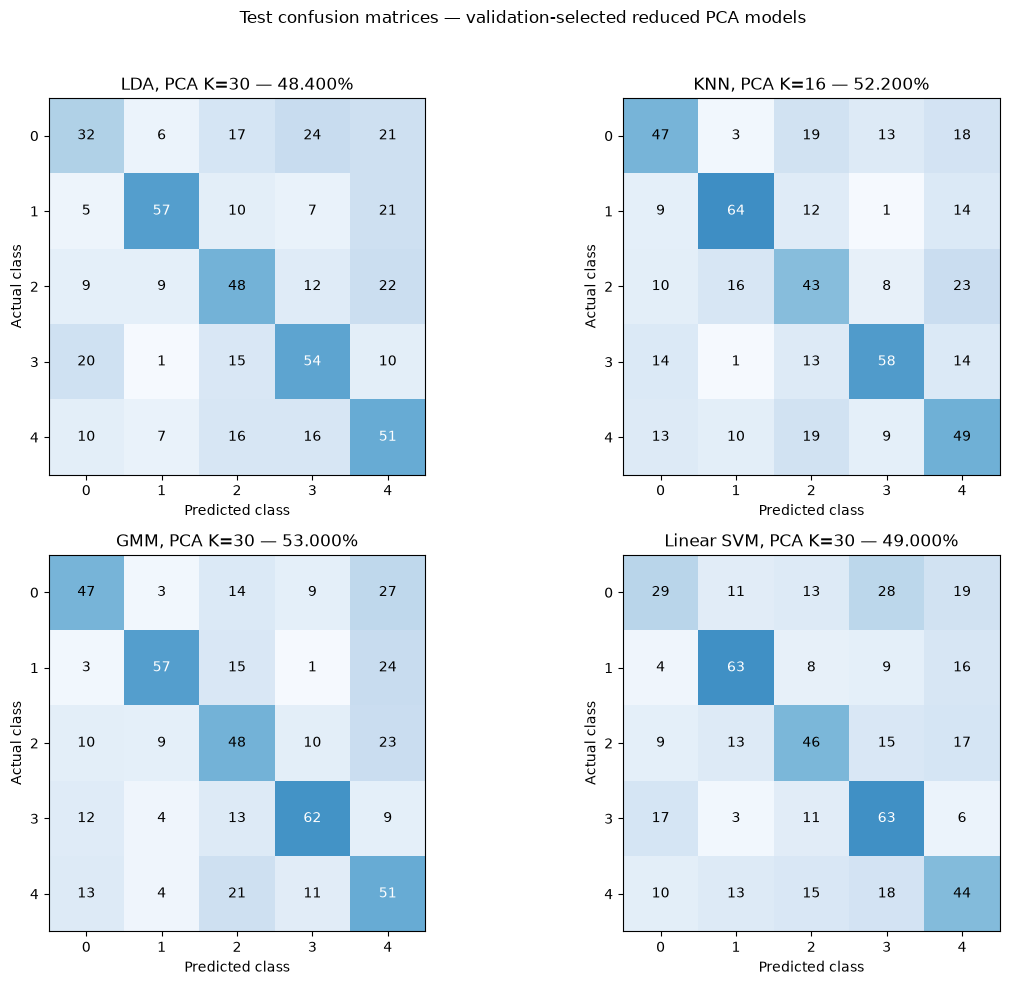

In [99]:
# Plot test confusion matrices for validation-selected reduced models.
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, classifier in zip(axes.flat, classifier_names):
    K = selected_reduced_K[classifier]
    predictions = pca_test_predictions[K][classifier]

    accuracy = 100 * accuracy_score_manual(
        y_test,
        predictions
    )

    plot_confusion_matrix_manual(
        ax,
        y_test,
        predictions,
        f"{classifier}, PCA K={K} — {accuracy:.3f}%"
    )

fig.suptitle(
    "Test confusion matrices — validation-selected reduced PCA models"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [100]:
# Calculate metrics for the selected reduced PCA models.
reduced_metric_rows = []
reduced_macro_rows = []

for classifier in classifier_names:
    K = selected_reduced_K[classifier]
    predictions = pca_test_predictions[K][classifier]

    class_metrics = classification_metrics_manual(
        y_test,
        predictions
    )

    for row in class_metrics:
        reduced_metric_rows.append({
            "Classifier": classifier,
            "K": K,
            **row
        })

    reduced_macro_rows.append({
        "Classifier": classifier,
        "K": K,
        "Test accuracy (%)": (
            100 * accuracy_score_manual(y_test, predictions)
        ),
        "Macro precision": np.mean([
            row["Precision"] for row in class_metrics
        ]),
        "Macro recall": np.mean([
            row["Recall"] for row in class_metrics
        ]),
        "Macro F1": np.mean([
            row["F1-score"] for row in class_metrics
        ])
    })

reduced_test_metrics = pd.DataFrame(
    reduced_metric_rows
)

reduced_macro_metrics = pd.DataFrame(
    reduced_macro_rows
)

print("Selected reduced PCA models — metrics by class:")
print(
    reduced_test_metrics.round(4).to_string(index=False)
)

print("\nSelected reduced PCA models — macro metrics:")
print(
    reduced_macro_metrics.round(4).to_string(index=False)
)

Selected reduced PCA models — metrics by class:
Classifier  K  Class  Precision  Recall  F1-score  Support
       LDA 30      0     0.4211    0.32    0.3636      100
       LDA 30      1     0.7125    0.57    0.6333      100
       LDA 30      2     0.4528    0.48    0.4660      100
       LDA 30      3     0.4779    0.54    0.5070      100
       LDA 30      4     0.4080    0.51    0.4533      100
       KNN 16      0     0.5054    0.47    0.4870      100
       KNN 16      1     0.6809    0.64    0.6598      100
       KNN 16      2     0.4057    0.43    0.4175      100
       KNN 16      3     0.6517    0.58    0.6138      100
       KNN 16      4     0.4153    0.49    0.4495      100
       GMM 30      0     0.5529    0.47    0.5081      100
       GMM 30      1     0.7403    0.57    0.6441      100
       GMM 30      2     0.4324    0.48    0.4550      100
       GMM 30      3     0.6667    0.62    0.6425      100
       GMM 30      4     0.3806    0.51    0.4359      100
Linear S

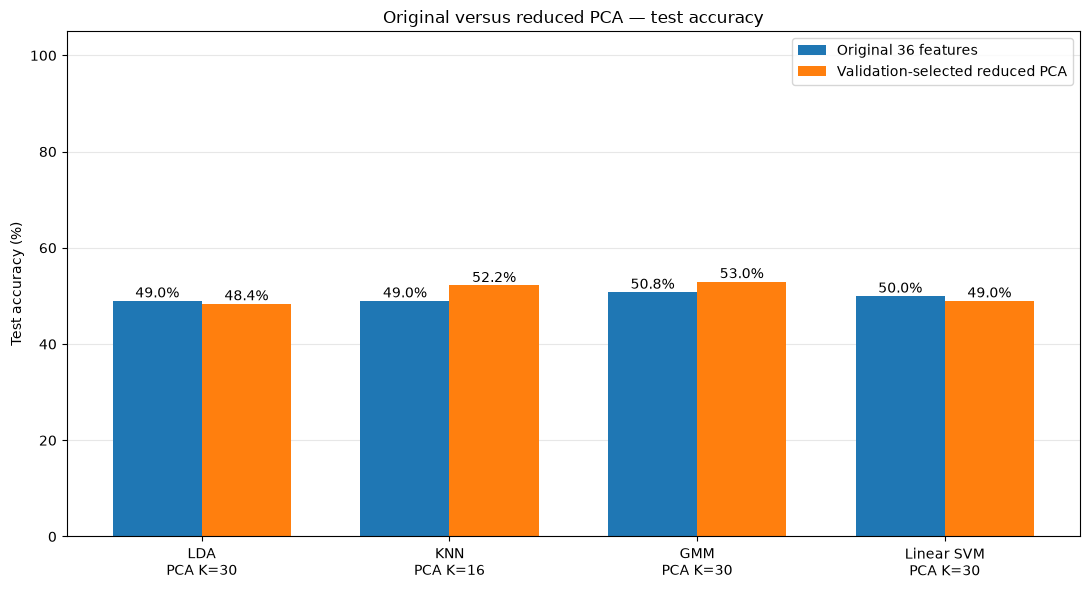

In [101]:
# Compare original and validation-selected reduced PCA test accuracies.
original_values = []
reduced_values = []
reduced_labels = []

for classifier in classifier_names:
    K = selected_reduced_K[classifier]

    original_values.append(
        original_test_accuracies[classifier]
    )

    reduced_values.append(
        100 * accuracy_score_manual(
            y_test,
            pca_test_predictions[K][classifier]
        )
    )

    reduced_labels.append(
        f"{classifier}\nPCA K={K}"
    )

positions = np.arange(len(classifier_names))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 6))

original_bars = ax.bar(
    positions - width / 2,
    original_values,
    width,
    label=f"Original {n_features} features",
    color="tab:blue"
)

reduced_bars = ax.bar(
    positions + width / 2,
    reduced_values,
    width,
    label="Validation-selected reduced PCA",
    color="tab:orange"
)

for bars in [original_bars, reduced_bars]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.7,
            f"{bar.get_height():.1f}%",
            ha="center"
        )

ax.set_xticks(positions)
ax.set_xticklabels(reduced_labels)
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 105)
ax.set_title("Original versus reduced PCA — test accuracy")
ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [102]:
# Print final observations using existing results.
print("FINAL OBSERVATIONS")
print("-" * 70)

for classifier in classifier_names:
    K = selected_reduced_K[classifier]

    original_accuracy = original_test_accuracies[classifier]

    reduced_predictions = pca_test_predictions[K][classifier]

    reduced_accuracy = (
        100 * accuracy_score_manual(
            y_test,
            reduced_predictions
        )
    )

    change = reduced_accuracy - original_accuracy
    dimensions_removed = 100 * (n_features - K) / n_features

    retained_variance = (
        100 * pca_model.cumulative_variance_[K - 1]
    )

    print(f"\n{classifier}")
    print(f"  Original test accuracy: {original_accuracy:.3f}%")
    print(f"  Validation-selected reduced K: {K}")
    print(f"  Dimensions removed: {dimensions_removed:.3f}%")
    print(f"  Training variance retained: {retained_variance:.3f}%")
    print(f"  Reduced PCA test accuracy: {reduced_accuracy:.3f}%")
    print(f"  Accuracy change: {change:+.3f} percentage points")

print("\nCONCLUSION")
print("-" * 70)
print(
    "LDA, KNN, GMM, and a one-versus-rest linear SVM were "
    "compared using the original features and PCA projections. "
    "Preprocessing and model fitting used training data, while "
    "model settings and reduced dimensions were selected using "
    "validation data. The held-out test results show whether "
    "dimensionality reduction helped each classifier."
)

print(
    "\nThese final cells summarize existing predictions; "
    "they do not retrain models or select settings using test data."
)

FINAL OBSERVATIONS
----------------------------------------------------------------------

LDA
  Original test accuracy: 49.000%
  Validation-selected reduced K: 30
  Dimensions removed: 16.667%
  Training variance retained: 94.978%
  Reduced PCA test accuracy: 48.400%
  Accuracy change: -0.600 percentage points

KNN
  Original test accuracy: 49.000%
  Validation-selected reduced K: 16
  Dimensions removed: 55.556%
  Training variance retained: 77.995%
  Reduced PCA test accuracy: 52.200%
  Accuracy change: +3.200 percentage points

GMM
  Original test accuracy: 50.800%
  Validation-selected reduced K: 30
  Dimensions removed: 16.667%
  Training variance retained: 94.978%
  Reduced PCA test accuracy: 53.000%
  Accuracy change: +2.200 percentage points

Linear SVM
  Original test accuracy: 50.000%
  Validation-selected reduced K: 30
  Dimensions removed: 16.667%
  Training variance retained: 94.978%
  Reduced PCA test accuracy: 49.000%
  Accuracy change: -1.000 percentage points

CONCLU

In [103]:
results = pca_results_table.melt(
    id_vars="K",
    value_vars=["LDA", "KNN", "GMM", "Linear SVM"],
    var_name="Classifier",
    value_name="Accuracy"
)

best_pca = results.sort_values(
    ["Accuracy", "K", "Classifier"],
    ascending=[False, True, True]
).iloc[0]

print("BEST PCA MODEL")
print("-------------------------")
print("Classifier:", best_pca["Classifier"])
print("PCA Components:", int(best_pca["K"]))
print(f"Validation Accuracy: {best_pca['Accuracy']:.3f}%")

BEST PCA MODEL
-------------------------
Classifier: GMM
PCA Components: 30
Validation Accuracy: 55.600%


In [104]:
selected_K = int(best_pca["K"])
selected_classifier = best_pca["Classifier"]

selected_test_accuracy = pca_test_table.set_index("K").loc[
    selected_K, selected_classifier
]

print("FINAL TEST RESULTS")
print("-------------------------")
print("Best Classifier:", selected_classifier)
print("PCA Components:", selected_K)
print(f"Test Accuracy: {selected_test_accuracy:.3f}%")

FINAL TEST RESULTS
-------------------------
Best Classifier: GMM
PCA Components: 30
Test Accuracy: 53.000%


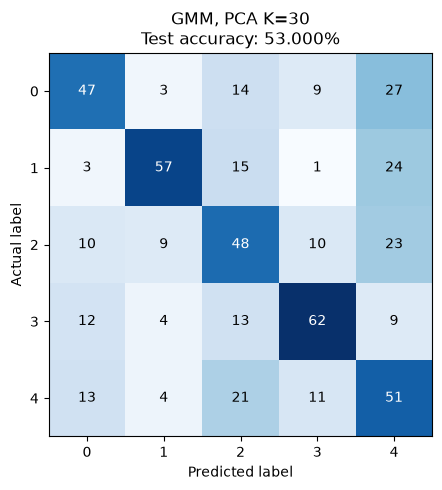

In [105]:
predictions = pca_test_predictions[selected_K][selected_classifier]

matrix = confusion_matrix_manual(y_test, predictions)
labels = np.unique(np.concatenate([y_test, predictions]))

plt.figure(figsize=(6, 5))
plt.imshow(matrix, cmap="Blues")

for row in range(len(labels)):
    for column in range(len(labels)):
        plt.text(
            column, row, matrix[row, column],
            ha="center",
            va="center",
            color="white" if matrix[row, column] > matrix.max() / 2
            else "black"
        )

plt.xticks(range(len(labels)), labels)
plt.yticks(range(len(labels)), labels)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title(
    f"{selected_classifier}, PCA K={selected_K}\n"
    f"Test accuracy: {selected_test_accuracy:.3f}%"
)
plt.tight_layout()
plt.show()

## Discussion and Conclusion

Using all 36 features, GMM achieved 50.8% test accuracy,
linear SVM achieved 50%, and LDA and KNN each achieved 49%.

PCA improved GMM accuracy to 53% with 30 components and KNN
accuracy to 52.2% with 16 components. Using too few components
reduced accuracy by removing useful class information.

GMM with 30 components retained by PCA was selected using
validation accuracy and achieved the highest reported test
accuracy. Overall, PCA provided modest improvements for GMM
and KNN, while classification remained challenging.